<a href="https://colab.research.google.com/github/faiqnabil/Pembelajaran-Mesin-2026/blob/main/TG9_244107020025_M_Faiq_Nabil_Saputra_JS09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Praktikum 1**

Langkah 1 — Load Data

In [8]:

# Load data
import pandas as pd
from google.colab import files
import io

uploaded = files.upload()

nama_file = list(uploaded.keys())[0]
data = pd.read_csv(io.BytesIO(uploaded[nama_file]))

data.head()


Saving iris.csv to iris (3).csv


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Langkah 2 — Eksplorasi Data

In [9]:

data.info()
data.describe()
data['species'].value_counts()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


Lanjutkan ke Langkah 3 — Visualisasi Data

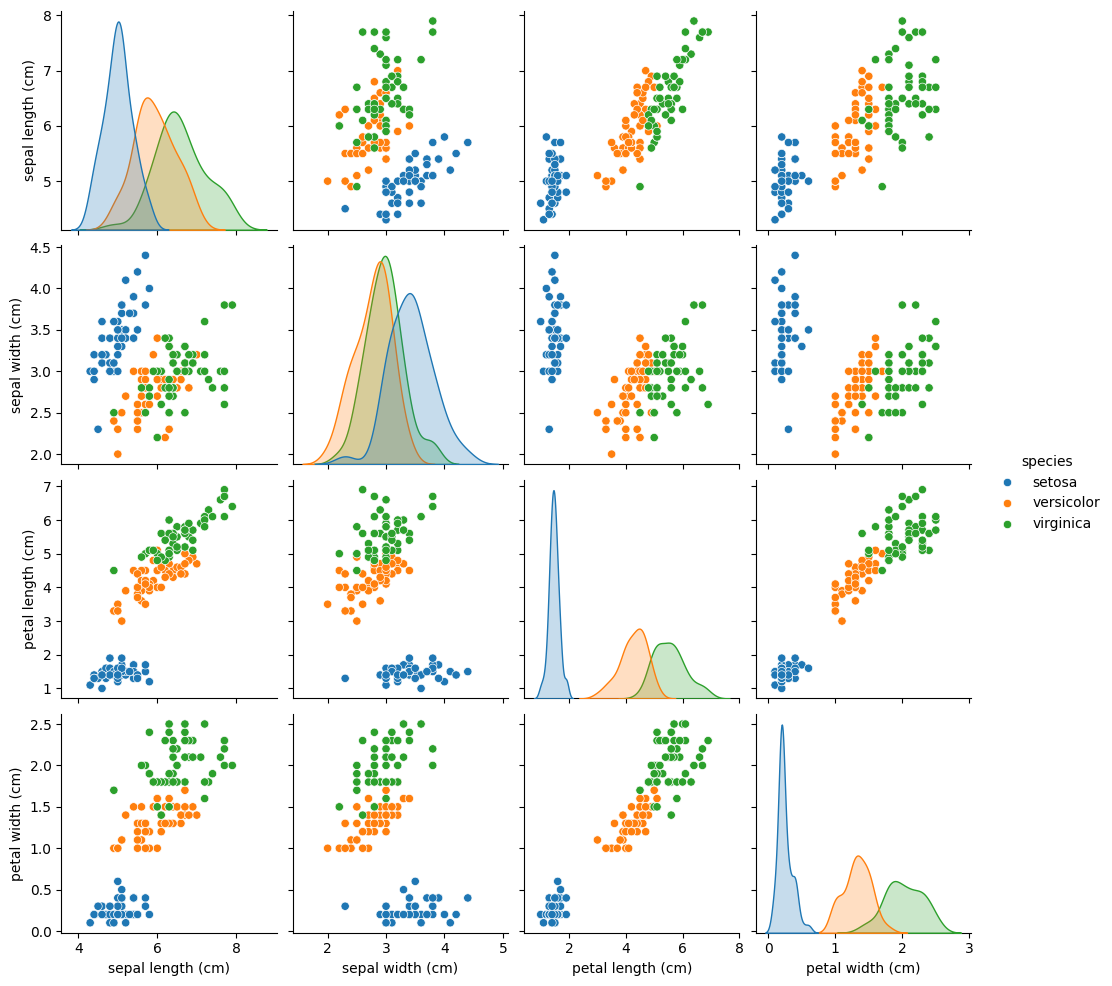

In [10]:

import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(data, hue='species')
plt.show()


Langkah 4 — Preprocessing

In [11]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]   # semua kolom kecuali label
y = data.iloc[:, -1]    # kolom label terakhir

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


Langkah 5 — Buat Model kNN

In [12]:

from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)


KNeighborsClassifier(n_neighbors=3)

Langkah 6 — Evaluasi Model kNN

In [13]:

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)

print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))


Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



Langkah 7 — Evaluasi Nilai K

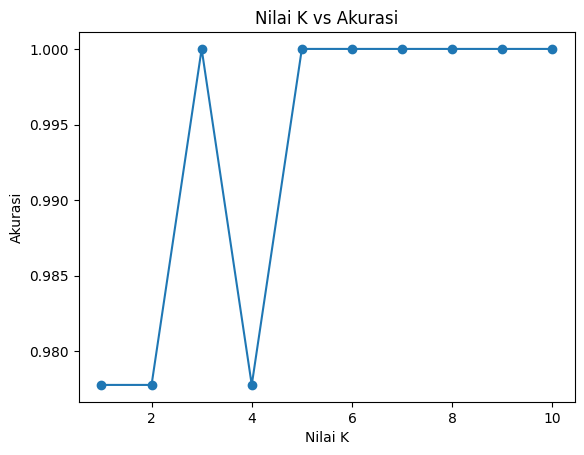

In [14]:

acc = []

for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()


## **Praktikum 2**

Langkah 1 — Buat Dataset Dummy

In [15]:

import numpy as np
from sklearn.datasets import make_classification

# Membuat data dummy
# Hasil dari make_classification berupa data fitur X dan label y
# Label y akan berupa data yang sudah di encode (angka)
X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)
# Secara defalt, make_classfication menghasilkan nilai float
# Kita perlu merubah dalam bentuk diskrit

# Absolutekan nilai
X = np.absolute(X)

# Bulatkan nilai ke 2 angka dibelakang koma
# Kalikan dengan 100 supaya tidak ada lagi koma
X = np.round(X, 2) * 100

# Ubah ke dalam bentuk integer
X = X.astype(int)
# Cek Hasil
print(X)
print(y)


[[ 71  64]
 [ 72  75]
 [ 81  97]
 [ 83  11]
 [180 157]
 [ 97  84]
 [145 141]
 [259 294]
 [ 80 166]
 [112  34]
 [108 103]
 [113   5]
 [101 103]
 [112  27]
 [ 79 169]
 [ 90 161]
 [225 185]
 [ 81  33]
 [ 90  35]
 [ 31  90]
 [170 161]
 [137 178]
 [180 192]
 [100 222]
 [105  94]
 [125 182]
 [148 336]
 [ 92 169]
 [114  51]
 [ 28 133]]
[0 0 1 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


Langkah 2 — Membuat DataFrame (Opsional)

In [16]:

import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)
# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()


,Fitur 1,Fitur 2,Label
0,71,64,0
1,72,75,0
2,81,97,1
3,83,11,0
4,180,157,0


Langkah 3 — Labeling (Opsional)

In [17]:

# Definisikan nama label
labels = {
    1 : 'Kelas A',
    0 : 'Kelas B'
}
# Copy Data Frame untuk menyimpan Data Frame baru
# dengan label yang mudah untuk dibaca
df_label = df.copy()

# Ubah label dengan fungsi mapping dari Pandas
# pada Data Frame df_label
df_label['Label'] = df_label['Label'].map(labels)

# Cek Data Frame df_label
df_label.head()


,Fitur 1,Fitur 2,Label
0,71,64,Kelas B
1,72,75,Kelas B
2,81,97,Kelas A
3,83,11,Kelas B
4,180,157,Kelas B


Langkah 4 — Visualisasi Data

/tmp/ipykernel_1017/1627498392.py:10: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_1017/1627498392.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


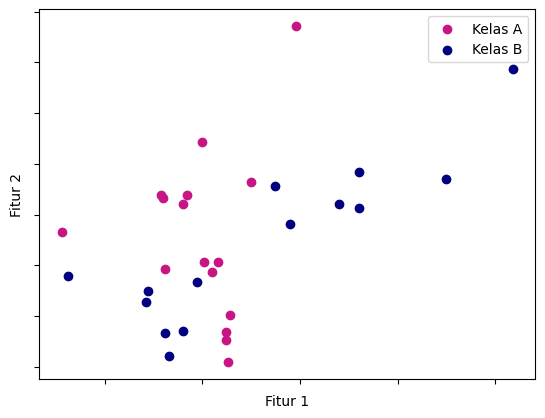

In [18]:

import matplotlib.pyplot as plt
# Definisikan warna untuk setiap kelas
colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

# Kelompokkan label berdasarkan nama kelas
gb = df_label.groupby(['Label'])
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')
# Plot
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()


Langkah 5 — Model Multinomial Naive Bayes

In [19]:

from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()

# Kita dapat langsung menggunakan fitur X dan label y
# hasil dari proses pembuatan data dummy

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

# Fit model
# Label y harus dalam bentuk 1D atau (n_samples,)
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred = mnb.predict(X_train)

# Evaluasi akurasi training
acc_train = accuracy_score(y_train, y_train_pred)
# Prediksi test data
y_test_pred = mnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test = accuracy_score(y_test, y_test_pred)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')


Hasil akurasi data train: 0.6190476190476191
Hasil akurasi data test: 0.6666666666666666


Langkah 6 — Model Gaussian Naive Bayes

In [20]:

from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Kita menggunakan split data training dan testing
# yang sama dengan model multinomial
# Fit model
# Label y harus dalam bentu 1D atau (n_samples,)
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi akurasi test data
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)
# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')


Hasil akurasi data train (Gaussian): 0.7142857142857143
Hasil akurasi data test (Gaussian): 0.6666666666666666


## **Praktikum 3**

Langkah 1 — Load Data

In [21]:

# Load data
import numpy as np
import pandas as pd
from google.colab import files
import io

uploaded = files.upload()

nama_file = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[nama_file]), encoding='latin-1')

df.head()


Saving spam.csv to spam.csv


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


Langkah 2 — Preprocessing

Langkah 2a — Drop Kolom

In [22]:

# Drop 3 kolom terakhir dengan fungsi iloc
df = df.drop(df.iloc[:, 2:], axis=1)

# Cek data
df.head()


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Langkah 2b — Inspeksi Data

In [23]:

# Ubah nama kolom sesuai kebutuhan pemodelan
df.columns = ['Labels', 'SMS']

# Cek jumlah data per kelas
print(df['Labels'].value_counts())
print('\n')

# Cek kelengkapan data
print(df.info())
print('\n')

# Cek statistik deskriptif
print(df.describe())


Labels
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


Langkah 2c — Encoding Label

In [24]:

# Data untuk label
new_labels = {
    'spam': 1,
    'ham': 0
}

# Encode label
df['Labels'] = df['Labels'].map(new_labels)

# Cek data
df.head()


,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


Langkah 2d — Pisahkan Fitur dengan Label

In [25]:

X = df['SMS'].values
y = df['Labels'].values


Langkah 3 — Ekstraksi Fitur

In [26]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50
)

# Inisiasi CountVectorizer
bow = CountVectorizer()

# Fitting dan transform X_train dengan CountVectorizer
X_train = bow.fit_transform(X_train)

# Transform X_test
X_test = bow.transform(X_test)


In [27]:

print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')


7727
Dimensi data: (4457, 7727)


Langkah 4 — Training dan Evaluasi Model

In [28]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Inisiasi MultinomialNB
mnb = MultinomialNB()

# Fit model
mnb.fit(X_train, y_train)

# Prediksi data training
y_pred_train = mnb.predict(X_train)

# Evaluasi akurasi data training
acc_train = accuracy_score(y_train, y_pred_train)

# Prediksi data testing
y_pred_test = mnb.predict(X_test)

# Evaluasi akurasi data testing
acc_test = accuracy_score(y_test, y_pred_test)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')


Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


## **Tugas 1**

Langkah 1 — Unduh dan unggah dataset

In [29]:

# Load dataset
import pandas as pd
import numpy as np
import io
from google.colab import files

uploaded = files.upload()

nama_file = list(uploaded.keys())[0]
data = pd.read_csv(io.BytesIO(uploaded[nama_file]))

data.head()


Saving voice.csv to voice.csv


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


Langkah 2 — Eksplorasi dataset

In [30]:

# Memeriksa struktur dataset
data.info()

# Menampilkan nama seluruh kolom
print(data.columns.tolist())

# Memeriksa jumlah data
print("Dimensi dataset:", data.shape)

# Memeriksa jumlah setiap kelas
print(data['label'].value_counts())

# Memeriksa data kosong
print(data.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   obje

Langkah 3 — Menyiapkan fitur dan label

In [31]:

# Memisahkan fitur dan label
X = data.drop(columns=['label'])
y = data['label']

print("Dimensi fitur:", X.shape)
print("Jumlah label:", y.shape)


Dimensi fitur: (3168, 20)
Jumlah label: (3168,)


Langkah 4 — Membagi data dan membangun model kNN

In [32]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Membagi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardisasi fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Membuat dan melatih model kNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Prediksi
y_pred = knn.predict(X_test_scaled)

# Evaluasi
print("Akurasi:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Akurasi: 0.9763406940063092
              precision    recall  f1-score   support

      female       0.99      0.97      0.98       317
        male       0.97      0.99      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



Langkah 5 — Eksperimen pemilihan fitur

In [33]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Membagi data satu kali agar perbandingan konsisten
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

hasil_fitur = []

# Menguji setiap fitur secara individual
for fitur in X.columns:
    X_train_fitur = X_train[[fitur]]
    X_test_fitur = X_test[[fitur]]

    scaler_fitur = StandardScaler()
    X_train_scaled = scaler_fitur.fit_transform(X_train_fitur)
    X_test_scaled = scaler_fitur.transform(X_test_fitur)

    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train_scaled, y_train)

    prediksi = model.predict(X_test_scaled)
    akurasi = accuracy_score(y_test, prediksi)

    hasil_fitur.append({
        'Fitur': fitur,
        'Akurasi': akurasi
    })

# Mengurutkan hasil dari akurasi tertinggi
tabel_fitur = pd.DataFrame(hasil_fitur)
tabel_fitur = tabel_fitur.sort_values(
    by='Akurasi',
    ascending=False
)

display(tabel_fitur)


,Fitur,Akurasi
12,meanfun,0.952681
5,IQR,0.902208
3,Q25,0.858044
1,sd,0.794953
8,sp.ent,0.712934
10,mode,0.692429
9,sfm,0.681388
16,mindom,0.608833
2,median,0.594637
7,kurt,0.591483


In [34]:

from itertools import combinations

fitur_kandidat = tabel_fitur['Fitur'].head(5).tolist()
hasil_kombinasi = []

for jumlah in range(1, len(fitur_kandidat) + 1):
    for kombinasi in combinations(fitur_kandidat, jumlah):

        scaler_kombinasi = StandardScaler()

        X_train_kombinasi = scaler_kombinasi.fit_transform(
            X_train[list(kombinasi)]
        )
        X_test_kombinasi = scaler_kombinasi.transform(
            X_test[list(kombinasi)]
        )

        model = KNeighborsClassifier(n_neighbors=5)
        model.fit(X_train_kombinasi, y_train)

        prediksi = model.predict(X_test_kombinasi)

        hasil_kombinasi.append({
            'Fitur': ', '.join(kombinasi),
            'Jumlah Fitur': jumlah,
            'Akurasi': accuracy_score(y_test, prediksi)
        })

tabel_kombinasi = pd.DataFrame(hasil_kombinasi)
tabel_kombinasi = tabel_kombinasi.sort_values(
    by='Akurasi',
    ascending=False
)

display(tabel_kombinasi)


,Fitur,Jumlah Fitur,Akurasi
27,"meanfun, IQR, sd, sp.ent",4,0.987382
16,"meanfun, IQR, sd",3,0.981073
25,"meanfun, IQR, Q25, sd",4,0.981073
17,"meanfun, IQR, sp.ent",3,0.981073
30,"meanfun, IQR, Q25, sd, sp.ent",5,0.981073
28,"meanfun, Q25, sd, sp.ent",4,0.977918
5,"meanfun, IQR",2,0.977918
19,"meanfun, Q25, sp.ent",3,0.977918
15,"meanfun, IQR, Q25",3,0.977918
26,"meanfun, IQR, Q25, sp.ent",4,0.976341


Langkah 6 — Menentukan nilai \(k\) terbaik

,Nilai k,Akurasi
0,1,0.976341
1,2,0.977918
2,3,0.984227
3,4,0.982650
4,5,0.987382
5,6,0.984227
6,7,0.979495
7,8,0.977918
8,9,0.976341
9,10,0.979495


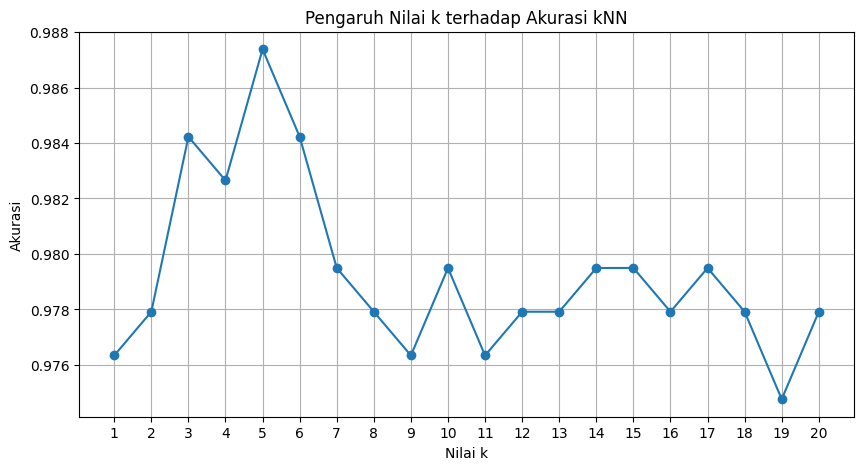

Fitur terpilih: ['meanfun', 'IQR', 'sd', 'sp.ent']
Nilai k terbaik: 5
Akurasi terbaik: 0.9873817034700315


In [35]:

import matplotlib.pyplot as plt

# Mengambil kombinasi fitur terbaik
fitur_terbaik = tabel_kombinasi.iloc[0]['Fitur'].split(', ')

# Menyiapkan fitur terpilih
scaler_terbaik = StandardScaler()

X_train_terpilih = scaler_terbaik.fit_transform(
    X_train[fitur_terbaik]
)
X_test_terpilih = scaler_terbaik.transform(
    X_test[fitur_terbaik]
)

hasil_k = []

# Menguji nilai k dari 1 sampai 20
for k in range(1, 21):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_terpilih, y_train)

    prediksi = model.predict(X_test_terpilih)
    akurasi = accuracy_score(y_test, prediksi)

    hasil_k.append({
        'Nilai k': k,
        'Akurasi': akurasi
    })

tabel_k = pd.DataFrame(hasil_k)
display(tabel_k)

# Grafik analisis nilai k
plt.figure(figsize=(10, 5))
plt.plot(
    tabel_k['Nilai k'],
    tabel_k['Akurasi'],
    marker='o'
)
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.title('Pengaruh Nilai k terhadap Akurasi kNN')
plt.xticks(range(1, 21))
plt.grid(True)
plt.show()

# Menampilkan nilai k dengan akurasi tertinggi
hasil_terbaik = tabel_k.loc[tabel_k['Akurasi'].idxmax()]

print("Fitur terpilih:", fitur_terbaik)
print("Nilai k terbaik:", int(hasil_terbaik['Nilai k']))
print("Akurasi terbaik:", hasil_terbaik['Akurasi'])


Langkah 7 — Visualisasi Hasil

7.1 Visualisasi akurasi berdasarkan nilai \(k\)

In [46]:
print(type(hasil_k))
print(hasil_k)

<class 'list'>
[{'Nilai k': 1, 'Akurasi': 0.9763406940063092}, {'Nilai k': 2, 'Akurasi': 0.9779179810725552}, {'Nilai k': 3, 'Akurasi': 0.9842271293375394}, {'Nilai k': 4, 'Akurasi': 0.9826498422712934}, {'Nilai k': 5, 'Akurasi': 0.9873817034700315}, {'Nilai k': 6, 'Akurasi': 0.9842271293375394}, {'Nilai k': 7, 'Akurasi': 0.9794952681388013}, {'Nilai k': 8, 'Akurasi': 0.9779179810725552}, {'Nilai k': 9, 'Akurasi': 0.9763406940063092}, {'Nilai k': 10, 'Akurasi': 0.9794952681388013}, {'Nilai k': 11, 'Akurasi': 0.9763406940063092}, {'Nilai k': 12, 'Akurasi': 0.9779179810725552}, {'Nilai k': 13, 'Akurasi': 0.9779179810725552}, {'Nilai k': 14, 'Akurasi': 0.9794952681388013}, {'Nilai k': 15, 'Akurasi': 0.9794952681388013}, {'Nilai k': 16, 'Akurasi': 0.9779179810725552}, {'Nilai k': 17, 'Akurasi': 0.9794952681388013}, {'Nilai k': 18, 'Akurasi': 0.9779179810725552}, {'Nilai k': 19, 'Akurasi': 0.9747634069400631}, {'Nilai k': 20, 'Akurasi': 0.9779179810725552}]


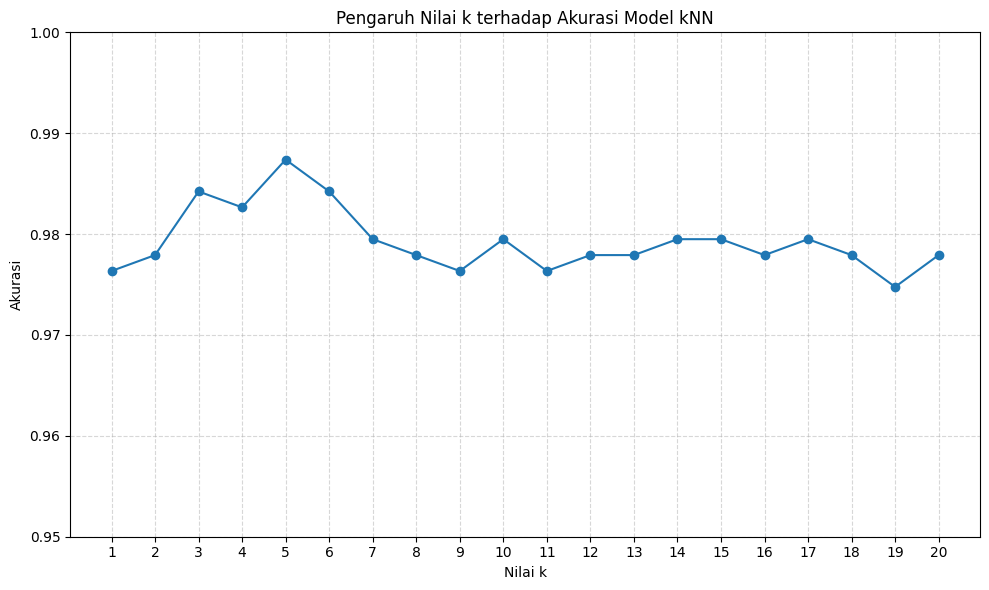

In [50]:
import pandas as pd
import matplotlib.pyplot as plt

# Mengubah list menjadi DataFrame
df_hasil_k = pd.DataFrame(hasil_k)

# Visualisasi akurasi berdasarkan nilai k
plt.figure(figsize=(10, 6))

plt.plot(
    df_hasil_k['Nilai k'],
    df_hasil_k['Akurasi'],
    marker='o'
)

plt.title('Pengaruh Nilai k terhadap Akurasi Model kNN')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.xticks(df_hasil_k['Nilai k'])
plt.ylim(0.95, 1.00)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

7.2 Visualisasi Akurasi Berdasarkan Fitur

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

# Mengubah hasil eksperimen fitur menjadi DataFrame
df_hasil_fitur = pd.DataFrame(hasil_fitur)

# Memeriksa struktur dan nama kolom
display(df_hasil_fitur)
print("Nama kolom:", df_hasil_fitur.columns.tolist())

,Fitur,Akurasi
0,meanfreq,0.586751
1,sd,0.794953
2,median,0.594637
3,Q25,0.858044
4,Q75,0.561514
5,IQR,0.902208
6,skew,0.588328
7,kurt,0.591483
8,sp.ent,0.712934
9,sfm,0.681388


Nama kolom: ['Fitur', 'Akurasi']


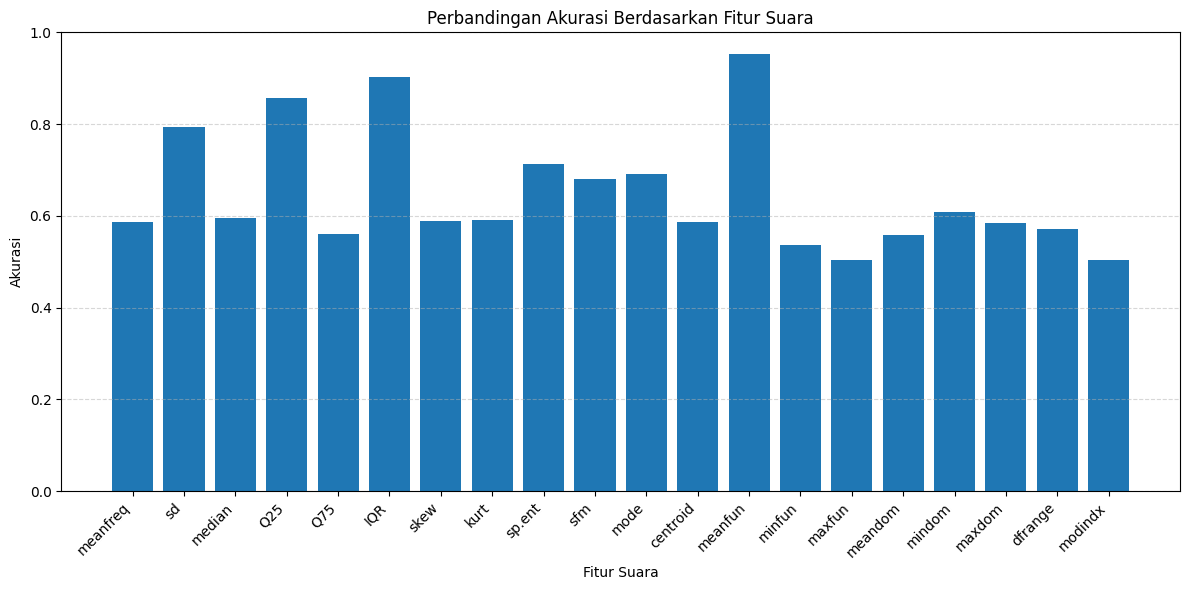

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    df_hasil_fitur['Fitur'].astype(str),
    df_hasil_fitur['Akurasi']
)

plt.title('Perbandingan Akurasi Berdasarkan Fitur Suara')
plt.xlabel('Fitur Suara')
plt.ylabel('Akurasi')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Langkah 8 — Menyusun kesimpulan tugas

Kesimpulan menggunakan hasil aktual notebook Anda dengan struktur berikut.
1. Model klasifikasi: kNN digunakan untuk membedakan suara laki-laki (male) dan perempuan (female).
2. Fitur optimal: sebutkan fitur atau kombinasi fitur yang menghasilkan akurasi tertinggi pada eksperimen.
3. Nilai \(k\) terbaik: tuliskan nilai \(k\) dan akurasi pengujiannya.
4. Analisis grafik: jelaskan perubahan akurasi saat nilai \(k\) bertambah dan alasan pemilihan nilai terbaik.

## **Tugas 2**

Langkah 1 — Memuat dataset

In [36]:

# Load data
import pandas as pd
import numpy as np
from google.colab import files
import io

uploaded = files.upload()

nama_file = list(uploaded.keys())[0]
df = pd.read_csv(
    io.BytesIO(uploaded[nama_file]),
    encoding='latin-1'
)

# Menghapus kolom yang tidak digunakan
df = df.iloc[:, :2].copy()
df.columns = ['Labels', 'SMS']

# Encoding label
df['Labels'] = df['Labels'].map({
    'spam': 1,
    'ham': 0
})

# Memisahkan fitur dan label
X = df['SMS'].values
y = df['Labels'].values

df.head()


Saving spam.csv to spam (1).csv


,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


Langkah 2 — Membagi data latih dan data uji

In [37]:

from sklearn.model_selection import train_test_split

# Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=50,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))


Jumlah data training: 4457
Jumlah data testing: 1115


Langkah 3 — Model Multinomial Naive Bayes dengan CountVectorizer

3.1. Membuat fitur CountVectorizer

In [38]:

from sklearn.feature_extraction.text import CountVectorizer

# Inisiasi CountVectorizer dengan stop_words
bow = CountVectorizer(stop_words='english')

# Fitting dan transform data training
X_train_bow = bow.fit_transform(X_train)

# Transform data testing
X_test_bow = bow.transform(X_test)

print("Dimensi data training:", X_train_bow.shape)
print("Dimensi data testing:", X_test_bow.shape)


Dimensi data training: (4457, 7422)
Dimensi data testing: (1115, 7422)


3.2. Melatih dan mengevaluasi model

In [39]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Inisiasi model
mnb_bow = MultinomialNB()

# Training model
mnb_bow.fit(X_train_bow, y_train)

# Prediksi data training
y_pred_train_bow = mnb_bow.predict(X_train_bow)

# Evaluasi data training
acc_train_bow = accuracy_score(y_train, y_pred_train_bow)

# Prediksi data testing
y_pred_test_bow = mnb_bow.predict(X_test_bow)

# Evaluasi data testing
acc_test_bow = accuracy_score(y_test, y_pred_test_bow)

print("Akurasi training CountVectorizer:", acc_train_bow)
print("Akurasi testing CountVectorizer:", acc_test_bow)

print("\nLaporan klasifikasi CountVectorizer:")
print(classification_report(
    y_test,
    y_pred_test_bow,
    target_names=['ham', 'spam']
))


Akurasi training CountVectorizer: 0.9939421135292797
Akurasi testing CountVectorizer: 0.9820627802690582

Laporan klasifikasi CountVectorizer:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.91      0.93       149

    accuracy                           0.98      1115
   macro avg       0.97      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



Langkah 4 — Model Multinomial Naive Bayes dengan TF-IDF

4.1. Membuat fitur TF-IDF

In [40]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Inisiasi TF-IDF dengan stop_words
tfidf = TfidfVectorizer(stop_words='english')

# Fitting dan transform data training
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform data testing
X_test_tfidf = tfidf.transform(X_test)

print("Dimensi data training:", X_train_tfidf.shape)
print("Dimensi data testing:", X_test_tfidf.shape)


Dimensi data training: (4457, 7422)
Dimensi data testing: (1115, 7422)


4.2. Melatih dan mengevaluasi model

In [41]:

# Inisiasi model
mnb_tfidf = MultinomialNB()

# Training model
mnb_tfidf.fit(X_train_tfidf, y_train)

# Prediksi data training
y_pred_train_tfidf = mnb_tfidf.predict(X_train_tfidf)

# Evaluasi data training
acc_train_tfidf = accuracy_score(
    y_train,
    y_pred_train_tfidf
)

# Prediksi data testing
y_pred_test_tfidf = mnb_tfidf.predict(X_test_tfidf)

# Evaluasi data testing
acc_test_tfidf = accuracy_score(
    y_test,
    y_pred_test_tfidf
)

print("Akurasi training TF-IDF:", acc_train_tfidf)
print("Akurasi testing TF-IDF:", acc_test_tfidf)

print("\nLaporan klasifikasi TF-IDF:")
print(classification_report(
    y_test,
    y_pred_test_tfidf,
    target_names=['ham', 'spam']
))


Akurasi training TF-IDF: 0.9842943684092439
Akurasi testing TF-IDF: 0.9730941704035875

Laporan klasifikasi TF-IDF:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.80      0.89       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.94      1115
weighted avg       0.97      0.97      0.97      1115



Langkah 5 — Membandingkan kedua model

In [42]:

# Membandingkan hasil kedua model
hasil_perbandingan = pd.DataFrame({
    'Metode': [
        'CountVectorizer',
        'TF-IDF'
    ],
    'Akurasi Training': [
        acc_train_bow,
        acc_train_tfidf
    ],
    'Akurasi Testing': [
        acc_test_bow,
        acc_test_tfidf
    ]
})

display(hasil_perbandingan)

# Menentukan metode dengan akurasi testing tertinggi
if acc_test_bow > acc_test_tfidf:
    print("Akurasi testing tertinggi: CountVectorizer")
elif acc_test_tfidf > acc_test_bow:
    print("Akurasi testing tertinggi: TF-IDF")
else:
    print("Kedua metode memiliki akurasi testing yang sama.")


,Metode,Akurasi Training,Akurasi Testing
0,CountVectorizer,0.993942,0.982063
1,TF-IDF,0.984294,0.973094


Akurasi testing tertinggi: CountVectorizer


Langkah 6 — Visualisasi Hasil Perbandingan

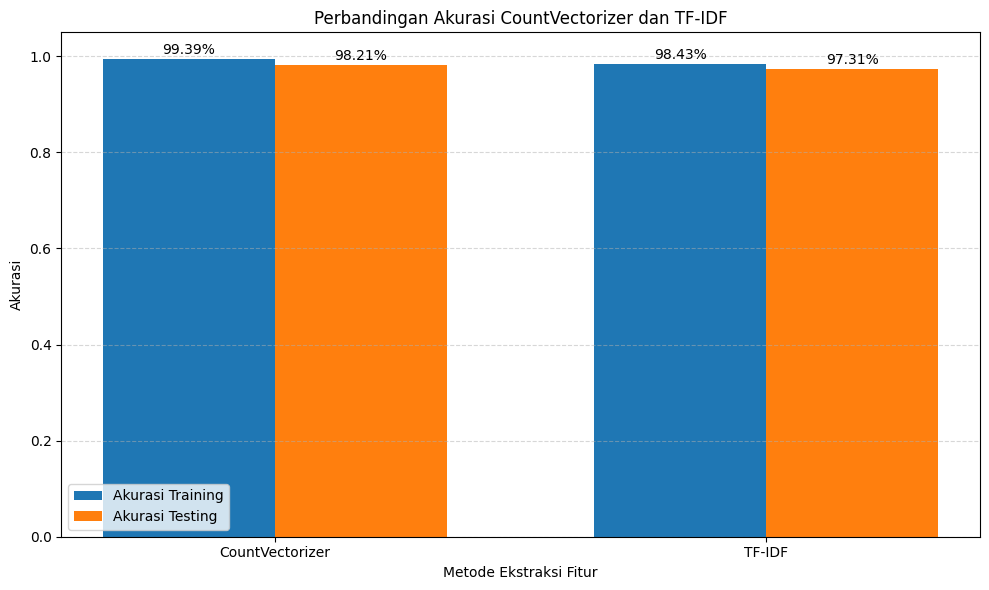

In [43]:
import matplotlib.pyplot as plt
import numpy as np

# Data hasil evaluasi
metode = ['CountVectorizer', 'TF-IDF']
akurasi_training = [acc_train_bow, acc_train_tfidf]
akurasi_testing = [acc_test_bow, acc_test_tfidf]

# Posisi batang pada grafik
x = np.arange(len(metode))
lebar = 0.35

# Membuat grafik
plt.figure(figsize=(10, 6))

plt.bar(
    x - lebar/2,
    akurasi_training,
    lebar,
    label='Akurasi Training'
)

plt.bar(
    x + lebar/2,
    akurasi_testing,
    lebar,
    label='Akurasi Testing'
)

# Memberikan judul dan label
plt.title('Perbandingan Akurasi CountVectorizer dan TF-IDF')
plt.xlabel('Metode Ekstraksi Fitur')
plt.ylabel('Akurasi')
plt.xticks(x, metode)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Menampilkan nilai akurasi di atas batang
for i, nilai in enumerate(akurasi_training):
    plt.text(
        x[i] - lebar/2,
        nilai + 0.01,
        f'{nilai:.2%}',
        ha='center'
    )

for i, nilai in enumerate(akurasi_testing):
    plt.text(
        x[i] + lebar/2,
        nilai + 0.01,
        f'{nilai:.2%}',
        ha='center'
    )

plt.tight_layout()
plt.show()

Langkah 7 — Kesimpulan tugas

Berdasarkan eksperimen klasifikasi SMS menggunakan algoritma Multinomial Naive Bayes, diperoleh hasil sebagai berikut.

1. **CountVectorizer dengan stop words** menghasilkan akurasi training sebesar **[isi hasil]** dan akurasi testing sebesar **[isi hasil]**.
2. **TF-IDF dengan stop words** menghasilkan akurasi training sebesar **[isi hasil]** dan akurasi testing sebesar **[isi hasil]**.
3. Berdasarkan hasil pengujian, metode **[isi metode dengan hasil terbaik]** memberikan performa yang lebih baik berdasarkan **[sebutkan metrik yang digunakan]**.
4. Perbedaan hasil terjadi karena CountVectorizer merepresentasikan frekuensi kemunculan kata, sedangkan TF-IDF memberikan bobot berdasarkan frekuensi kata dalam dokumen dan tingkat keumumannya dalam kumpulan dokumen.
5. Dengan demikian, metode yang dipilih sebagai representasi fitur terbaik untuk dataset `spam.csv` adalah **[isi berdasarkan hasil aktual]**, dengan mempertimbangkan akurasi serta precision, recall, dan F1-score kelas spam.